In [ ]:
# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully.")

from google.colab import drive
drive.mount('/content/drive')

Libraries imported successfully.
Mounted at /content/drive


In [ ]:
# ============================================================
# 4. CHECK GOOGLE DRIVE CONTENTS
# ============================================================

import os

mydrive_path = "/content/drive/MyDrive"

print("Files/folders directly inside MyDrive:\n")

for item in os.listdir(mydrive_path):
    print(item)

Files/folders directly inside MyDrive:

Colab Notebooks
2025-07-21_09-35-34 - user.mp4
To study I need a note including graphs charts an....gsheet
At the beginning of this note add a mind map to g... (2).gdoc
At the beginning of this note add a mind map to g... (1).gdoc
At the beginning of this note add a mind map to g....gdoc
Untitled presentation.gslides
Inventory Hub Use Case Scenario Generation.gsheet
Supplier Portal Use Case: Vendor Management (1).gsheet
Supplier Portal Use Case: Vendor Management.gsheet
Inventory usecase-Page-1.drawio.png
Inventory usecase.drawio
Lec 1-PDP.gdoc
SKU Registration Test Cases Generation.gsheet
Google AI Studio
Cognitive_IVMS_Final_Report.gdoc
Chanuthi Jayasingha.pdf
Untitled document (1).gdoc
Here are 3 unique, localized data science projects designed to grab the attention of Sri Lankan recruiters in both tech and non-tech sectors.gdoc
Untitled document.gdoc
Chanuthi_Jayasingha (1).pdf
Chanuthi_Jayasingha.pdf
DWBI Self-Study Tutorial Plan.gdoc
Start 

In [ ]:
# ============================================================
# TASK 7 - PRINCIPAL COMPONENT ANALYSIS (PCA)
# Evaluating PCA for Customer Behaviour Variables
# ============================================================

In [ ]:
# ============================================================
# 5. INSPECT THE SAVED STATISTICAL MODELLING FILES
# ============================================================

import os

mydrive_path = "/content/drive/MyDrive"

print("Statistical Modelling project items:\n")

for item in os.listdir(mydrive_path):

    if "Statistical Modelling Project" in item:

        full_path = os.path.join(mydrive_path, item)

        print("Name:", item)
        print("Full path:", full_path)
        print("Is folder:", os.path.isdir(full_path))
        print("Is file:", os.path.isfile(full_path))

        if os.path.isfile(full_path):
            print("File size:", os.path.getsize(full_path), "bytes")

        print("-" * 60)

Statistical Modelling project items:

Name: Statistical Modelling Project
Full path: /content/drive/MyDrive/Statistical Modelling Project
Is folder: True
Is file: False
------------------------------------------------------------
Name: Statistical Modelling Projectonline_retail_clean
Full path: /content/drive/MyDrive/Statistical Modelling Projectonline_retail_clean
Is folder: False
Is file: True
File size: 102115978 bytes
------------------------------------------------------------
Name: Statistical Modelling Projectonline_retail_merchandise
Full path: /content/drive/MyDrive/Statistical Modelling Projectonline_retail_merchandise
Is folder: False
Is file: True
File size: 84031045 bytes
------------------------------------------------------------
Name: Statistical Modelling Projectcustomer_level_data
Full path: /content/drive/MyDrive/Statistical Modelling Projectcustomer_level_data
Is folder: False
Is file: True
File size: 2053517 bytes
---------------------------------------------------

In [ ]:
# ============================================================
# 6. IDENTIFY THE CUSTOMER-LEVEL DATA FILE FORMAT
# ============================================================

customer_file = (
    "/content/drive/MyDrive/"
    "Statistical Modelling Projectcustomer_level_data"
)

# Read only the first few bytes of the file.
# This does NOT modify the file.
with open(customer_file, "rb") as f:
    first_bytes = f.read(100)

print("First bytes of the file:")
print(first_bytes)

First bytes of the file:
b'CustomerID,Frequency,Monetary,AverageOrderValue,TotalQuantity,AverageBasketQuantity,AverageUniquePro'


In [ ]:
# ============================================================
# 7. LOAD THE CUSTOMER-LEVEL DATASET
# ============================================================

import pandas as pd

customer_file = (
    "/content/drive/MyDrive/"
    "Statistical Modelling Projectcustomer_level_data"
)

# The file is CSV-formatted even though it has no .csv extension.
customer_level_data = pd.read_csv(customer_file)

print("Customer-level dataset loaded successfully.")
print("Dataset shape:", customer_level_data.shape)

print("\nAvailable columns:")
for column in customer_level_data.columns:
    print(column)

Customer-level dataset loaded successfully.
Dataset shape: (5863, 32)

Available columns:
CustomerID
Frequency
Monetary
AverageOrderValue
TotalQuantity
AverageBasketQuantity
AverageUniqueProducts
FirstPurchaseDate
LastPurchaseDate
Recency
CustomerTenure
ProductDiversity
ReturnTransactions
ReturnedQuantity
TotalReturnValue
ReturnRate
AveragePurchaseInterval
ActivePurchaseDays
OrdersPerActiveDay
Log_TotalReturnValue
Log_AverageOrderValue
Log_AverageBasketQuantity
Log_ReturnedQuantity
Log_Monetary
Log_TotalQuantity
Log_Frequency
Log_ReturnRate
Log_ReturnTransactions
Log_ActivePurchaseDays
Log_OrdersPerActiveDay
Log_ProductDiversity
Log_AverageUniqueProducts


In [ ]:
# Display the first five customer records
display(customer_level_data.head())


,CustomerID,Frequency,Monetary,AverageOrderValue,TotalQuantity,AverageBasketQuantity,AverageUniqueProducts,FirstPurchaseDate,LastPurchaseDate,Recency,...,Log_ReturnedQuantity,Log_Monetary,Log_TotalQuantity,Log_Frequency,Log_ReturnRate,Log_ReturnTransactions,Log_ActivePurchaseDays,Log_OrdersPerActiveDay,Log_ProductDiversity,Log_AverageUniqueProducts
0,12346.0,4,77353.96,19338.49000,74240,18560.000000,6.500000,2009-12-18 10:55:00,2011-01-18 10:01:00,326,...,11.214762,11.256160,11.215072,1.609438,0.692721,1.386294,1.609438,0.693147,3.295837,2.014903
1,12347.0,8,4921.53,615.19125,2967,370.875000,27.750000,2010-10-31 14:20:00,2011-12-07 15:52:00,2,...,0.000000,8.501578,7.995644,2.197225,0.000000,0.000000,2.197225,0.693147,4.844187,3.358638
2,12348.0,5,1658.40,331.68000,2704,540.800000,8.400000,2010-09-27 14:59:00,2011-09-25 13:13:00,75,...,0.000000,7.414211,7.902857,1.791759,0.000000,0.000000,1.791759,0.693147,3.218876,2.240710
3,12349.0,3,3678.69,1226.23000,1621,540.333333,57.333333,2010-04-29 13:20:00,2011-11-21 09:51:00,19,...,1.791759,8.210584,7.391415,1.386294,0.006543,0.693147,1.386294,0.693147,4.927254,4.066174
4,12350.0,1,294.40,294.40000,196,196.000000,16.000000,2011-02-02 16:01:00,2011-02-02 16:01:00,310,...,0.000000,5.688330,5.283204,0.693147,0.000000,0.000000,0.693147,0.693147,2.833213,2.833213


In [ ]:
# ============================================================
# 8. INSPECT ALL CUSTOMER-LEVEL VARIABLES
# ============================================================

print("Dataset shape:", customer_level_data.shape)
print("\nAll available columns:\n")

for i, column in enumerate(customer_level_data.columns, start=1):
    print(f"{i}. {column}")

Dataset shape: (5863, 32)

All available columns:

1. CustomerID
2. Frequency
3. Monetary
4. AverageOrderValue
5. TotalQuantity
6. AverageBasketQuantity
7. AverageUniqueProducts
8. FirstPurchaseDate
9. LastPurchaseDate
10. Recency
11. CustomerTenure
12. ProductDiversity
13. ReturnTransactions
14. ReturnedQuantity
15. TotalReturnValue
16. ReturnRate
17. AveragePurchaseInterval
18. ActivePurchaseDays
19. OrdersPerActiveDay
20. Log_TotalReturnValue
21. Log_AverageOrderValue
22. Log_AverageBasketQuantity
23. Log_ReturnedQuantity
24. Log_Monetary
25. Log_TotalQuantity
26. Log_Frequency
27. Log_ReturnRate
28. Log_ReturnTransactions
29. Log_ActivePurchaseDays
30. Log_OrdersPerActiveDay
31. Log_ProductDiversity
32. Log_AverageUniqueProducts


In [ ]:
# ============================================================
# 9. SELECT VARIABLES FOR PCA
# ============================================================

# Select one representative version of each customer behaviour.
#
# Log-transformed versions are used for highly skewed variables
# where these transformations were already created during the
# earlier exploratory analysis.
#
# CustomerID and purchase dates are excluded because they are
# identifiers/time stamps rather than behavioural measurements.
#
# We also avoid including both the original and log-transformed
# version of the same variable because that would duplicate
# information in the PCA.

pca_features = [
    'Log_Frequency',
    'Log_Monetary',
    'Log_AverageOrderValue',
    'Log_AverageBasketQuantity',
    'Log_AverageUniqueProducts',
    'Recency',
    'CustomerTenure',
    'Log_ProductDiversity',
    'Log_ReturnTransactions',
    'Log_ReturnRate'
]

X_pca = customer_level_data[pca_features].copy()

print("PCA dataset shape:", X_pca.shape)

print("\nSelected PCA variables:")
for i, feature in enumerate(pca_features, start=1):
    print(f"{i}. {feature}")

PCA dataset shape: (5863, 10)

Selected PCA variables:
1. Log_Frequency
2. Log_Monetary
3. Log_AverageOrderValue
4. Log_AverageBasketQuantity
5. Log_AverageUniqueProducts
6. Recency
7. CustomerTenure
8. Log_ProductDiversity
9. Log_ReturnTransactions
10. Log_ReturnRate


In [ ]:
# ============================================================
# 10. CHECK PCA DATA QUALITY
# ============================================================

print("Missing values:")
print(X_pca.isnull().sum())

print("\nInfinite values:")
print(
    pd.Series(
        np.isinf(X_pca).sum(),
        index=X_pca.columns
    )
)

print("\nDataset shape:")
print(X_pca.shape)

Missing values:
Log_Frequency                0
Log_Monetary                 0
Log_AverageOrderValue        0
Log_AverageBasketQuantity    0
Log_AverageUniqueProducts    0
Recency                      0
CustomerTenure               0
Log_ProductDiversity         0
Log_ReturnTransactions       0
Log_ReturnRate               0
dtype: int64

Infinite values:
Log_Frequency                0
Log_Monetary                 0
Log_AverageOrderValue        0
Log_AverageBasketQuantity    0
Log_AverageUniqueProducts    0
Recency                      0
CustomerTenure               0
Log_ProductDiversity         0
Log_ReturnTransactions       0
Log_ReturnRate               0
dtype: int64

Dataset shape:
(5863, 10)


Correlation Matrix:


,Log_Frequency,Log_Monetary,Log_AverageOrderValue,Log_AverageBasketQuantity,Log_AverageUniqueProducts,Recency,CustomerTenure,Log_ProductDiversity,Log_ReturnTransactions,Log_ReturnRate
Log_Frequency,1.00,0.85,0.21,0.19,0.08,-0.50,0.81,0.68,0.67,0.02
Log_Monetary,0.85,1.00,0.69,0.58,0.31,-0.48,0.72,0.75,0.62,0.02
Log_AverageOrderValue,0.21,0.69,1.00,0.82,0.47,-0.18,0.20,0.44,0.26,0.00
Log_AverageBasketQuantity,0.19,0.58,0.82,1.00,0.47,-0.21,0.18,0.43,0.21,-0.01
Log_AverageUniqueProducts,0.08,0.31,0.47,0.47,1.00,-0.14,0.11,0.76,0.09,-0.12
Recency,-0.50,-0.48,-0.18,-0.21,-0.14,1.00,-0.56,-0.43,-0.29,0.03
CustomerTenure,0.81,0.72,0.20,0.18,0.11,-0.56,1.00,0.61,0.52,0.01
Log_ProductDiversity,0.68,0.75,0.44,0.43,0.76,-0.43,0.61,1.00,0.47,-0.07
Log_ReturnTransactions,0.67,0.62,0.26,0.21,0.09,-0.29,0.52,0.47,1.00,0.28
Log_ReturnRate,0.02,0.02,0.00,-0.01,-0.12,0.03,0.01,-0.07,0.28,1.00


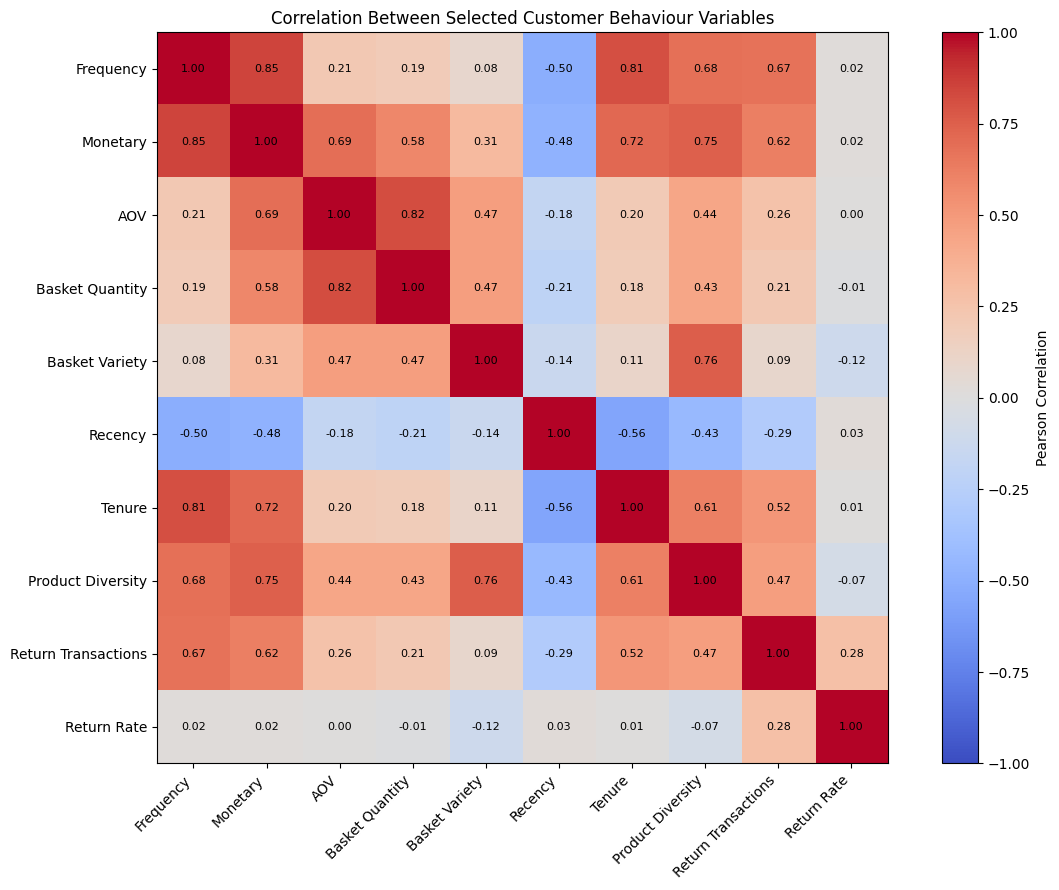

In [ ]:
# ============================================================
# 11. CORRELATION ANALYSIS BEFORE PCA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Pearson correlation is appropriate here because PCA
# examines linear relationships between variables.

correlation_matrix = X_pca.corr(method='pearson')

print("Correlation Matrix:")
display(correlation_matrix.round(2))


# Create a correlation heatmap
fig, ax = plt.subplots(figsize=(12, 9))

im = ax.imshow(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

# Use shorter labels to make the graph easier to read.
short_labels = [
    'Frequency',
    'Monetary',
    'AOV',
    'Basket Quantity',
    'Basket Variety',
    'Recency',
    'Tenure',
    'Product Diversity',
    'Return Transactions',
    'Return Rate'
]

ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))

ax.set_xticklabels(
    short_labels,
    rotation=45,
    ha='right'
)

ax.set_yticklabels(short_labels)

# Show the correlation coefficient inside each cell.
for i in range(len(short_labels)):
    for j in range(len(short_labels)):
        ax.text(
            j, i,
            f'{correlation_matrix.iloc[i, j]:.2f}',
            ha='center',
            va='center',
            fontsize=8
        )

plt.colorbar(
    im,
    ax=ax,
    label='Pearson Correlation'
)

plt.title(
    'Correlation Between Selected Customer Behaviour Variables'
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 12. IDENTIFY THE STRONGEST CORRELATIONS
# ============================================================

# Keep only the upper half of the correlation matrix
# to avoid listing each variable pair twice.

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    'Variable 1',
    'Variable 2',
    'Correlation'
]

# Sort by absolute correlation strength.
correlation_pairs['Absolute Correlation'] = (
    correlation_pairs['Correlation'].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    'Absolute Correlation',
    ascending=False
)

print("Top 10 strongest correlation pairs:")

display(
    correlation_pairs.head(10).round(3)
)

Top 10 strongest correlation pairs:


,Variable 1,Variable 2,Correlation,Absolute Correlation
0,Log_Frequency,Log_Monetary,0.849,0.849
17,Log_AverageOrderValue,Log_AverageBasketQuantity,0.817,0.817
5,Log_Frequency,CustomerTenure,0.810,0.810
32,Log_AverageUniqueProducts,Log_ProductDiversity,0.757,0.757
14,Log_Monetary,Log_ProductDiversity,0.748,0.748
13,Log_Monetary,CustomerTenure,0.717,0.717
9,Log_Monetary,Log_AverageOrderValue,0.691,0.691
6,Log_Frequency,Log_ProductDiversity,0.685,0.685
7,Log_Frequency,Log_ReturnTransactions,0.673,0.673
15,Log_Monetary,Log_ReturnTransactions,0.625,0.625


In [ ]:
# ============================================================
# 13. STANDARDIZE VARIABLES BEFORE PCA
# ============================================================

from sklearn.preprocessing import StandardScaler

# PCA is sensitive to variable scale.
# Standardization gives each selected variable a mean of 0
# and a standard deviation of approximately 1, preventing
# variables with larger numerical scales from dominating PCA.

scaler_pca = StandardScaler()

X_pca_scaled = scaler_pca.fit_transform(X_pca)

# Convert back to a DataFrame so that we can easily
# inspect the standardized values.
X_pca_scaled_df = pd.DataFrame(
    X_pca_scaled,
    columns=pca_features
)

print("Standardized dataset shape:", X_pca_scaled_df.shape)

print("\nMean after standardization:")
display(X_pca_scaled_df.mean().round(3))

print("\nStandard deviation after standardization:")
display(X_pca_scaled_df.std().round(3))

Standardized dataset shape: (5863, 10)

Mean after standardization:


,0
Log_Frequency,0.0
Log_Monetary,-0.0
Log_AverageOrderValue,-0.0
Log_AverageBasketQuantity,0.0
Log_AverageUniqueProducts,-0.0
Recency,-0.0
CustomerTenure,0.0
Log_ProductDiversity,0.0
Log_ReturnTransactions,-0.0
Log_ReturnRate,0.0



Standard deviation after standardization:


,0
Log_Frequency,1.0
Log_Monetary,1.0
Log_AverageOrderValue,1.0
Log_AverageBasketQuantity,1.0
Log_AverageUniqueProducts,1.0
Recency,1.0
CustomerTenure,1.0
Log_ProductDiversity,1.0
Log_ReturnTransactions,1.0
Log_ReturnRate,1.0


In [ ]:
# ============================================================
# 14. RUN PRINCIPAL COMPONENT ANALYSIS
# ============================================================

from sklearn.decomposition import PCA

# Keep all 10 components initially.
# We first examine how much variance each component explains
# before deciding whether dimensionality reduction is useful.

pca = PCA()

X_pca_components = pca.fit_transform(X_pca_scaled)

print("PCA completed successfully.")
print("Number of original variables:", X_pca.shape[1])
print("Number of principal components:", pca.n_components_)

PCA completed successfully.
Number of original variables: 10
Number of principal components: 10


In [ ]:
# ============================================================
# 15. CALCULATE EXPLAINED VARIANCE
# ============================================================

# Percentage of total variance explained by each component
explained_variance = pca.explained_variance_ratio_

# Cumulative percentage explained as components are added
cumulative_variance = np.cumsum(explained_variance)

pca_variance_table = pd.DataFrame({
    'Principal Component': [
        f'PC{i+1}'
        for i in range(len(explained_variance))
    ],

    'Explained Variance (%)':
        explained_variance * 100,

    'Cumulative Variance (%)':
        cumulative_variance * 100
})

display(pca_variance_table.round(2))

,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,47.11,47.11
1,PC2,18.40,65.51
2,PC3,11.74,77.25
3,PC4,8.29,85.54
4,PC5,6.69,92.22
5,PC6,3.71,95.93
6,PC7,2.08,98.02
7,PC8,1.81,99.82
8,PC9,0.15,99.98
9,PC10,0.02,100.00


In [ ]:
# ============================================================
# 16. COMPONENTS REQUIRED FOR 80% AND 90% VARIANCE
# ============================================================

components_80 = np.argmax(
    cumulative_variance >= 0.80
) + 1

components_90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

print(
    "Components needed for at least 80% variance:",
    components_80
)

print(
    "Components needed for at least 90% variance:",
    components_90
)

Components needed for at least 80% variance: 4
Components needed for at least 90% variance: 5


In [ ]:
# ============================================================
# 17. CALCULATE PCA COMPONENT LOADINGS
# ============================================================

# PCA loadings show how strongly each original customer
# variable contributes to each principal component.
#
# Positive and negative signs show the direction of the
# relationship, while larger absolute values indicate
# stronger contributions.

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print("PCA Component Loadings:")
display(loadings.round(3))

PCA Component Loadings:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Log_Frequency,0.379,-0.349,-0.072,-0.031,0.224,-0.138,-0.233,-0.456,-0.435,-0.455
Log_Monetary,0.439,-0.023,0.072,-0.201,0.153,-0.153,-0.359,-0.061,-0.011,0.763
Log_AverageOrderValue,0.293,0.438,0.254,-0.335,0.021,-0.035,-0.372,0.482,0.035,-0.414
Log_AverageBasketQuantity,0.278,0.454,0.211,-0.328,-0.094,0.003,0.575,-0.474,0.006,-0.000
Log_AverageUniqueProducts,0.226,0.466,-0.189,0.605,-0.087,0.070,0.038,0.133,-0.534,0.114
Recency,-0.269,0.201,0.251,0.175,0.807,-0.359,0.119,0.007,0.004,0.006
CustomerTenure,0.352,-0.331,-0.157,-0.053,-0.029,-0.469,0.523,0.493,-0.045,-0.015
Log_ProductDiversity,0.400,0.094,-0.207,0.442,0.051,-0.087,-0.081,-0.173,0.722,-0.160
Log_ReturnTransactions,0.306,-0.272,0.337,0.126,0.322,0.717,0.220,0.190,0.023,0.016
Log_ReturnRate,0.010,-0.173,0.775,0.358,-0.389,-0.285,-0.065,-0.065,-0.010,-0.004


In [ ]:
# ============================================================
# 17. CREATE PC1 vs PC2 CUSTOMER SCATTER PLOT
# ============================================================

# Put the PCA scores into a DataFrame
pca_scores = pd.DataFrame(
    X_pca_components,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

# Add CustomerID only for reference.
# CustomerID was NOT used to calculate the PCA.
pca_scores['CustomerID'] = customer_level_data['CustomerID'].values

print("PCA score dataset shape:", pca_scores.shape)

display(pca_scores.head())

PCA score dataset shape: (5863, 11)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,CustomerID
0,4.734684,2.248592,11.187060,-1.365586,-2.719631,-3.002801,-0.291277,-0.183412,0.337436,-0.058847,12346.0
1,2.167092,0.921235,-0.587006,-0.554474,-0.607103,-0.674829,-0.496946,-0.323938,-0.081913,0.021588,12347.0
2,0.500369,0.273738,-0.075319,-1.615166,-0.554999,-0.491022,0.466925,-0.675462,-0.084740,0.056095,12348.0
3,2.831260,1.806283,-0.053782,-0.217207,-0.623001,-0.112510,0.297615,1.014822,-0.042104,0.028424,12349.0
4,-1.671401,1.207162,0.084112,-0.318634,-0.083116,0.223680,0.103856,-0.055305,-0.053853,-0.043755,12350.0


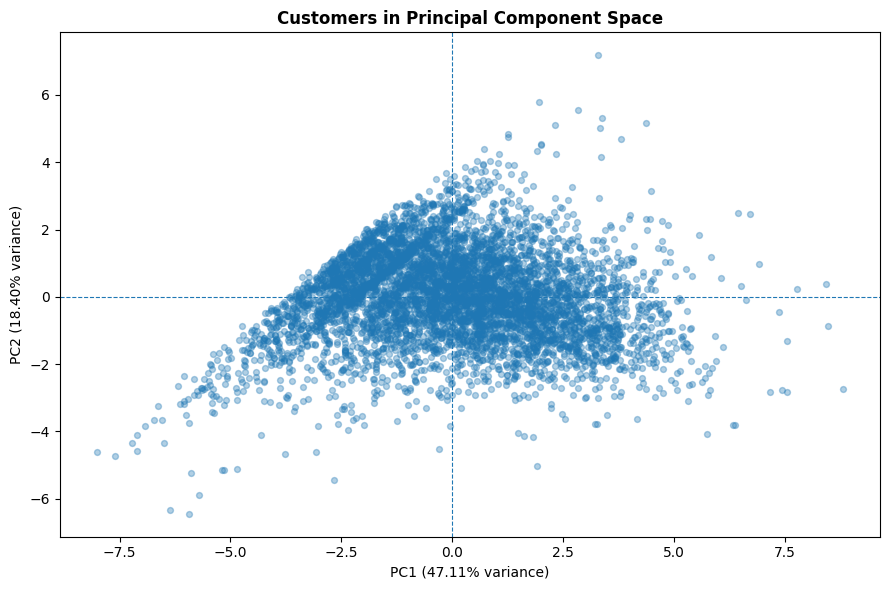

In [ ]:
# ============================================================
# 18. PLOT CUSTOMERS IN PCA SPACE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    pca_scores['PC1'],
    pca_scores['PC2'],
    alpha=0.35,
    s=18
)

plt.axhline(
    0,
    linewidth=0.8,
    linestyle='--'
)

plt.axvline(
    0,
    linewidth=0.8,
    linestyle='--'
)

plt.xlabel(
    f'PC1 ({explained_variance[0] * 100:.2f}% variance)'
)

plt.ylabel(
    f'PC2 ({explained_variance[1] * 100:.2f}% variance)'
)

plt.title(
    'Customers in Principal Component Space',
    fontweight='bold'
)

plt.tight_layout()
plt.show()

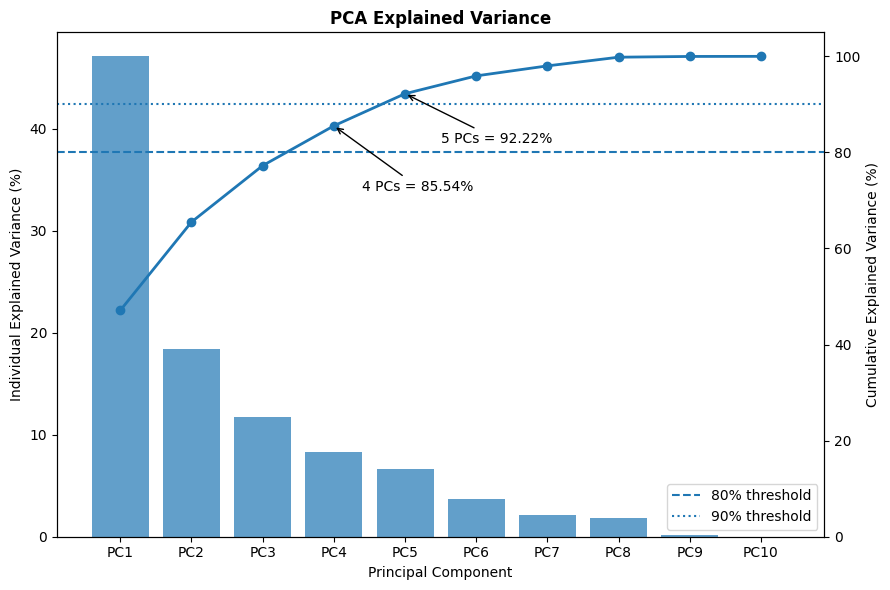

In [ ]:
# ============================================================
# 19. PCA EXPLAINED VARIANCE GRAPH
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

components = np.arange(1, len(explained_variance) + 1)

fig, ax1 = plt.subplots(figsize=(9, 6))

# ------------------------------------------------------------
# Bars = variance explained by each individual component
# ------------------------------------------------------------
ax1.bar(
    components,
    explained_variance * 100,
    alpha=0.7
)

ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Individual Explained Variance (%)')

ax1.set_xticks(components)
ax1.set_xticklabels(
    [f'PC{i}' for i in components]
)

# ------------------------------------------------------------
# Second axis = cumulative explained variance
# ------------------------------------------------------------
ax2 = ax1.twinx()

ax2.plot(
    components,
    cumulative_variance * 100,
    marker='o',
    linewidth=2
)

ax2.set_ylabel('Cumulative Explained Variance (%)')
ax2.set_ylim(0, 105)

# 80% reference line
ax2.axhline(
    y=80,
    linestyle='--',
    linewidth=1.5,
    label='80% threshold'
)

# 90% reference line
ax2.axhline(
    y=90,
    linestyle=':',
    linewidth=1.5,
    label='90% threshold'
)

# Highlight the important cumulative values
ax2.annotate(
    '4 PCs = 85.54%',
    xy=(4, cumulative_variance[3] * 100),
    xytext=(4.4, 72),
    arrowprops=dict(arrowstyle='->')
)

ax2.annotate(
    '5 PCs = 92.22%',
    xy=(5, cumulative_variance[4] * 100),
    xytext=(5.5, 82),
    arrowprops=dict(arrowstyle='->')
)

ax2.legend(loc='lower right')

plt.title(
    'PCA Explained Variance',
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PCA LOADINGS FOR PC1-PC4
# ============================================================

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

loadings_4 = loadings[['PC1', 'PC2', 'PC3', 'PC4']]

display(loadings_4.round(3))

,PC1,PC2,PC3,PC4
Log_Frequency,0.379,-0.349,-0.072,-0.031
Log_Monetary,0.439,-0.023,0.072,-0.201
Log_AverageOrderValue,0.293,0.438,0.254,-0.335
Log_AverageBasketQuantity,0.278,0.454,0.211,-0.328
Log_AverageUniqueProducts,0.226,0.466,-0.189,0.605
Recency,-0.269,0.201,0.251,0.175
CustomerTenure,0.352,-0.331,-0.157,-0.053
Log_ProductDiversity,0.400,0.094,-0.207,0.442
Log_ReturnTransactions,0.306,-0.272,0.337,0.126
Log_ReturnRate,0.010,-0.173,0.775,0.358


In [ ]:
# ============================================================
# 20. CREATE CUSTOMER VALUE SEGMENTS FOR PCA VISUALISATION
# ============================================================

# Create four customer-value groups using historical Monetary value.
# Quartiles are used so that customers are divided into four
# approximately equal-sized groups.
#
# IMPORTANT:
# These are descriptive historical customer-value segments.
# They are NOT predictions of future Customer Lifetime Value (CLV).

customer_level_data['CustomerValueSegment'] = pd.qcut(
    customer_level_data['Monetary'],
    q=4,
    labels=[
        'Low',
        'Medium',
        'High',
        'Very High'
    ]
)

print("Number of customers in each value segment:")
print(
    customer_level_data['CustomerValueSegment']
    .value_counts()
    .sort_index()
)

Number of customers in each value segment:
CustomerValueSegment
Low          1466
Medium       1466
High         1465
Very High    1466
Name: count, dtype: int64


In [ ]:
# ============================================================
# 21. ADD CUSTOMER VALUE SEGMENTS TO PCA SCORES
# ============================================================

pca_scores['CustomerValueSegment'] = (
    customer_level_data['CustomerValueSegment'].values
)

display(pca_scores.head())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,CustomerID,CustomerValueSegment
0,4.734684,2.248592,11.187060,-1.365586,-2.719631,-3.002801,-0.291277,-0.183412,0.337436,-0.058847,12346.0,Very High
1,2.167092,0.921235,-0.587006,-0.554474,-0.607103,-0.674829,-0.496946,-0.323938,-0.081913,0.021588,12347.0,Very High
2,0.500369,0.273738,-0.075319,-1.615166,-0.554999,-0.491022,0.466925,-0.675462,-0.084740,0.056095,12348.0,High
3,2.831260,1.806283,-0.053782,-0.217207,-0.623001,-0.112510,0.297615,1.014822,-0.042104,0.028424,12349.0,Very High
4,-1.671401,1.207162,0.084112,-0.318634,-0.083116,0.223680,0.103856,-0.055305,-0.053853,-0.043755,12350.0,Low


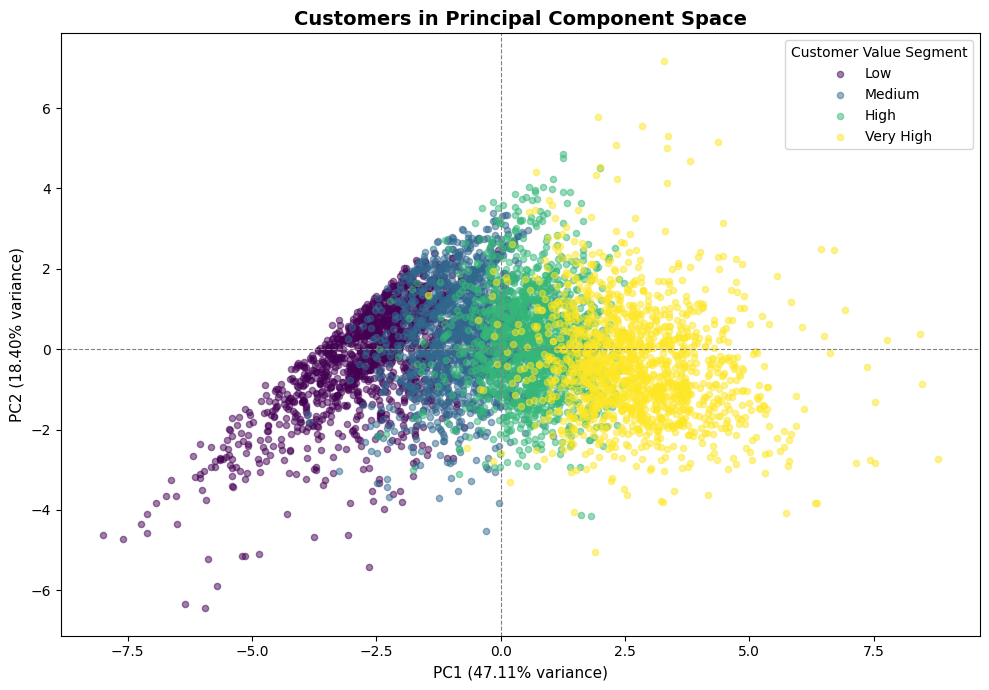

In [ ]:
# ============================================================
# 22. PCA SCATTER PLOT BY CUSTOMER VALUE SEGMENT
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Colours progress from lower to higher historical customer value
segment_colours = {
    'Low': '#440154',
    'Medium': '#31688e',
    'High': '#35b779',
    'Very High': '#fde725'
}

for segment in ['Low', 'Medium', 'High', 'Very High']:

    subset = pca_scores[
        pca_scores['CustomerValueSegment'] == segment
    ]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=segment,
        color=segment_colours[segment],
        alpha=0.50,
        s=20
    )

# Reference lines
plt.axhline(
    y=0,
    color='grey',
    linestyle='--',
    linewidth=0.8
)

plt.axvline(
    x=0,
    color='grey',
    linestyle='--',
    linewidth=0.8
)

# Use the actual explained variance from our PCA
plt.xlabel(
    'PC1 (47.11% variance)',
    fontsize=11
)

plt.ylabel(
    'PC2 (18.40% variance)',
    fontsize=11
)

plt.title(
    'Customers in Principal Component Space',
    fontsize=14,
    fontweight='bold'
)

plt.legend(
    title='Customer Value Segment',
    frameon=True
)

plt.tight_layout()
plt.show()